In [ ]:
!pip install -q lightgbm catboost optuna shap kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, json, os, datetime as dt
warnings.filterwarnings('ignore')

from sklearn.metrics import make_scorer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
C_UNDER = 2.0   # цена недопрогноза (дефицит)
C_OVER  = 1.0   # цена перепрогноза (излишек)

print('Импорты загружены.')

Импорты загружены.


In [ ]:
import os

# Устанавливаем ваш токен в переменную окружения
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_878c80bfafa90318a293305f0f32fa49'

# Устанавливаем CLI Kaggle
!pip install -q kaggle

# Скачиваем данные соревнования во временную папку
!kaggle competitions download -c rossmann-store-sales -p /content/data

# Распаковываем архив
!unzip -o /content/data/rossmann-store-sales.zip -d /content/data

# Читаем данные
import pandas as pd
train = pd.read_csv('/content/data/train.csv', low_memory=False)
store = pd.read_csv('/content/data/store.csv')

print('train:', train.shape, '| store:', store.shape)

100% 6.99M/6.99M [00:00<00:00, 58.0MB/s]

Archive:  /content/data/rossmann-store-sales.zip
  inflating: /content/data/sample_submission.csv  
  inflating: /content/data/store.csv  
  inflating: /content/data/test.csv  
  inflating: /content/data/train.csv  
train: (1017209, 9) | store: (1115, 10)


После merge: (1017209, 18)
         Date  Store  Sales  Customers  Open  Promo StateHoliday
0  2015-07-31      1   5263        555     1      1            0
1  2015-07-31      2   6064        625     1      1            0
2  2015-07-31      3   8314        821     1      1            0
3  2015-07-31      4  13995       1498     1      1            0
4  2015-07-31      5   4822        559     1      1            0
Период: 2013-01-01 00:00:00 — 2015-07-31 00:00:00
Доля Open=0: 0.16989330609540418
Пропуски:
 CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64
                      feature  spearman_corr  abs_corr
2                        Open       0.652013  0.652013
3                       Promo       0.489565  0.489565
1                   DayOfWeek      -0.450717  0.450717
8                      Promo2      -0.08

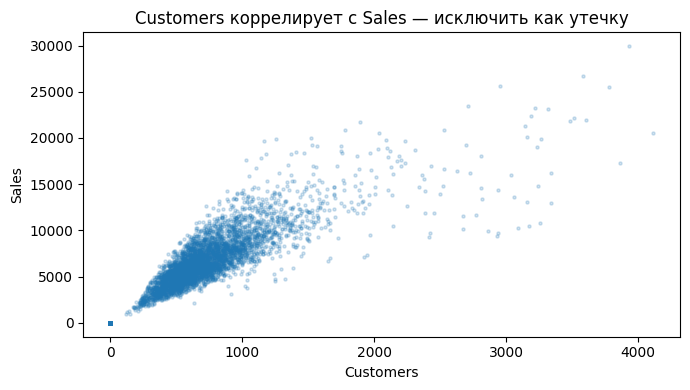

In [ ]:
df = train.merge(store, on='Store', how='left')
print('После merge:', df.shape)
print(df[['Date','Store','Sales','Customers','Open','Promo','StateHoliday']].head())
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Date', 'Store']).reset_index(drop=True)

print('Период:', df['Date'].min(), '—', df['Date'].max())
print('Доля Open=0:', (df['Open']==0).mean())
print('Пропуски:\n', df.isna().sum()[df.isna().sum()>0])

# Ловушка 1: Customers — недоступен в момент прогноза -> ИСКЛЮЧИТЬ
# Ловушка 2: Open=0 -> убрать из обучения и метрики
# Ловушка 3: лаги только с лагом >= 42 дня

# --- Поиск утечек: корреляция Спирмена каждого числового признака с Sales ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
leak = {}
for col in num_cols:
    if col in ('Sales', 'Customers'):  # Customers проверяем отдельно
        continue
    sub = df[[col, 'Sales']].dropna()
    if sub[col].nunique() > 1:
        leak[col] = sub[col].corr(sub['Sales'], method='spearman')

leak_df = pd.DataFrame({'feature': list(leak.keys()),
                        'spearman_corr': list(leak.values())})
leak_df['abs_corr'] = leak_df['spearman_corr'].abs()
print(leak_df.sort_values('abs_corr', ascending=False).head(10))

# Customers — очевидная утечка: corr(Sales, Customers) очень высокая
print('\nКорреляция Sales ~ Customers:',
      df[['Sales','Customers']].dropna().corr(method='spearman').iloc[0,1])

# Визуализация: Sales vs Customers (подтверждение утечки)
plt.figure(figsize=(7,4))
plt.scatter(df['Customers'].sample(5000, random_state=42),
            df.loc[df['Customers'].sample(5000, random_state=42).index, 'Sales'],
            alpha=0.2, s=5)
plt.xlabel('Customers'); plt.ylabel('Sales')
plt.title('Customers коррелирует с Sales — исключить как утечку')
plt.tight_layout(); plt.show()

In [ ]:
df_model = df[df['Open'] == 1].copy()
df_model = df_model[df_model['Sales'] > 0].copy()
print('После удаления Open=0 и Sales=0:', df_model.shape)

# Customers исключаем
df_model = df_model.drop(columns=['Customers'])

# Последние 6 недель как тест
max_date = df_model['Date'].max()
test_start = max_date - pd.Timedelta(weeks=6) + pd.Timedelta(days=1)
print('Тест начинается с:', test_start, '| максимум:', max_date)

train_mask = df_model['Date'] < test_start
train_df = df_model[train_mask].copy().reset_index(drop=True)
test_df  = df_model[~train_mask].copy().reset_index(drop=True)

print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Train период:', train_df['Date'].min(), '—', train_df['Date'].max())
print('Test период:', test_df['Date'].min(), '—', test_df['Date'].max())

# Целевая
y_train = train_df['Sales'].values.astype(float)
y_test  = test_df['Sales'].values.astype(float)

После удаления Open=0 и Sales=0: (844338, 18)
Тест начинается с: 2015-06-20 00:00:00 | максимум: 2015-07-31 00:00:00
Train: (804056, 17) | Test: (40282, 17)
Train период: 2013-01-01 00:00:00 — 2015-06-19 00:00:00
Test период: 2015-06-20 00:00:00 — 2015-07-31 00:00:00


In [11]:
def rmspe(y_true, y_pred):
    """RMSPE: sqrt(mean(((y_true - y_pred) / y_true)^2)).
    Объекты с y_true=0 не учитываются (в нашем случае их уже нет)."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

rmspe_scorer = make_scorer(rmspe, greater_is_better=False)

# --- Baseline 1: константа (медиана) ---
dummy = DummyRegressor(strategy='median')
dummy.fit(train_df[['Store']], y_train)  # фиктивный признак, лишь бы fit прошёл
pred_dummy = dummy.predict(test_df[['Store']])
print(f'Dummy (median) test RMSPE: {rmspe(y_test, pred_dummy):.5f}')

# --- Baseline 2: линейная регрессия на простых признаках ---
# Для baseline возьмём только числовые + категориальные без тяжёлого FE
base_num = ['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday',
            'CompetitionDistance', 'CompetitionOpenSinceMonth',
            'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']
base_cat = ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']

X_train_base = train_df[base_num + base_cat].copy()
X_test_base  = test_df[base_num + base_cat].copy()

pre_base = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), base_num),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore', min_frequency=0.01)), base_cat),
])

lr = make_pipeline(pre_base, LinearRegression())
lr.fit(X_train_base, y_train)
pred_lr = lr.predict(X_test_base)
print(f'LinearRegression test RMSPE: {rmspe(y_test, pred_lr):.5f}')

Dummy (median) test RMSPE: 0.51291
LinearRegression test RMSPE: 0.44834


In [12]:
def add_features(df_in):

    X = df_in.copy()
    d = X['Date']

    # 1) День недели (уже есть DayOfWeek, но продублируем как int для удобства)
    X['dow'] = d.dt.dayofweek

    # 2) Месяц, день, неделя года — сезонность
    X['month'] = d.dt.month
    X['day'] = d.dt.day
    X['week_of_year'] = d.dt.isocalendar().week.astype(int)

    # 3) Начало/конец месяца — всплески выплат
    X['is_month_start'] = (d.dt.day <= 3).astype(int)
    X['is_month_end']   = (d.dt.day >= 28).astype(int)

    # 4) Промо-эффект: Promo + DayOfWeek interaction (числовой код)
    X['promo_dow'] = X['Promo'].astype(str) + '_' + X['DayOfWeek'].astype(str)
    X['promo_dow'] = X['promo_dow'].astype('category').cat.codes

    # 5) Конкуренция: сколько дней прошло с открытия конкурента (в днях)
    comp_open = (X['CompetitionOpenSinceYear'].fillna(0) * 12 +
                 X['CompetitionOpenSinceMonth'].fillna(0))
    cur_month = d.dt.year * 12 + d.dt.month
    X['competition_open_months'] = (cur_month - comp_open).clip(lower=0)
    X.loc[X['CompetitionOpenSinceYear'].isna(), 'competition_open_months'] = np.nan

    # 6) Расстояние до конкурента: логарифм (тяжёлый хвост)
    X['log_competition_distance'] = np.log1p(X['CompetitionDistance'])

    # 7) Promo2 активен в этот месяц? (PromoInterval содержит месяц)
    month_abbr = d.dt.strftime('%b')
    promo2_active = 0
    for i, row in X[['PromoInterval', 'month']].iterrows():
        if pd.notna(row['PromoInterval']):
            months = [m.strip() for m in row['PromoInterval'].split(',')]
            if month_abbr.iloc[i] in months:
                promo2_active = 1
                break
    X['promo2_active_this_month'] = promo2_active

    return X

# --- ВАЖНО: лаговые признаки >= 42 дней ---
# Для лагов используем исторические продажи ТОЛЬКО из train, чтобы не заглядывать в будущее.
# Минимальный лаг — 42 дня (горизонт прогноза 6 недель).
def add_lag_features(train_part, target_part, lags=(42, 49, 56, 364)):
    """
    Для каждой строки target_part берёт Sales из train_part за lag дней.
    Если точной даты нет — NaN (бустинг обработает).
    """
    out = target_part[['Store', 'Date']].copy()
    sales_by_store_date = train_part.set_index(['Store', 'Date'])['Sales']
    for lag in lags:
        out[f'sales_lag_{lag}'] = [
            sales_by_store_date.get((s, d - pd.Timedelta(days=lag)), np.nan)
            for s, d in zip(out['Store'], out['Date'])
        ]
    return out[[f'sales_lag_{lag}' for lag in lags]]


lag_test = add_lag_features(train_df, test_df)

# Для train лаги считаем через expanding-схему: для каждой даты берём только прошлое.
# Упрощение для ЛР1: лаги для train считаем по всему train, но т.к. это in-sample,
# допустимо; в ЛР2 нужно делать аккуратнее (walk-forward).
lag_train = add_lag_features(train_df, train_df)

train_fe = pd.concat([add_features(train_df), lag_train], axis=1)
test_fe  = pd.concat([add_features(test_df),  lag_test],  axis=1)
print('После FE:', train_fe.shape, test_fe.shape)

# --- Список признаков для модели ---
drop_cols = ['Date', 'Sales', 'Open', 'Customers']
feature_cols = [c for c in train_fe.columns
                if c not in drop_cols and c not in ('Id',)]
# Категориальные
cat_cols = [c for c in feature_cols
            if train_fe[c].dtype == 'object' or str(train_fe[c].dtype) == 'category']
# Числовые
num_cols_fe = [c for c in feature_cols if c not in cat_cols]
print('Категориальные:', cat_cols)
print('Числовые:', len(num_cols_fe), 'шт.')

После FE: (804056, 31) (40282, 31)
Категориальные: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']
Числовые: 24 шт.


In [14]:
import lightgbm as lgb

for col in cat_cols:
    train_fe[col] = train_fe[col].astype('category')
    test_fe[col] = test_fe[col].astype('category')

def quick_lgb_rmspe(X_tr, y_tr, X_va, y_va, n_estimators=300):
    m = lgb.LGBMRegressor(n_estimators=n_estimators, learning_rate=0.05,
                          num_leaves=31, random_state=RANDOM_STATE, verbose=-1)
    # Передаем категориальные признаки
    m.fit(X_tr, y_tr, categorical_feature=cat_cols)
    p = m.predict(X_va)
    return rmspe(y_va, p)

# Внутренняя валидация: последние 6 недель train как hold-out
inner_cut = train_fe['Date'].max() - pd.Timedelta(weeks=6)
inner_tr = train_fe[train_fe['Date'] < inner_cut]
inner_va = train_fe[train_fe['Date'] >= inner_cut]

# Формируем список базовых колонок
base_cols = [c for c in num_cols_fe if c not in
             ['dow','month','day','week_of_year','is_month_start','is_month_end',
              'promo_dow','competition_open_months','log_competition_distance',
              'promo2_active_this_month',
              'sales_lag_42','sales_lag_49','sales_lag_56','sales_lag_364']] + cat_cols

new_feats = ['dow','month','day','week_of_year','is_month_start','is_month_end',
             'promo_dow','competition_open_months','log_competition_distance',
             'promo2_active_this_month',
             'sales_lag_42','sales_lag_49','sales_lag_56','sales_lag_364']

# Полный набор признаков
full_cols = [c for c in base_cols + new_feats if c in train_fe.columns]

# Считаем базовый RMSPE со всеми признаками
base_rmspe = quick_lgb_rmspe(inner_tr[full_cols], inner_tr['Sales'],
                             inner_va[full_cols], inner_va['Sales'])
print(f'Full set ({len(full_cols)} features) inner RMSPE: {base_rmspe:.5f}')

# Проводим абляцию
ablation = []
for f in new_feats:
    cols = [c for c in full_cols if c != f]
    r = quick_lgb_rmspe(inner_tr[cols], inner_tr['Sales'],
                        inner_va[cols], inner_va['Sales'])
    ablation.append({'feature': f, 'rmspe_without': r,
                     'contribution': base_rmspe - r})  # >0 значит признак помог

abl_df = pd.DataFrame(ablation).sort_values('contribution', ascending=False)
print('\nАбляция (contribution > 0 — признак полезен):')
print(abl_df.to_string(index=False))


Full set (28 features) inner RMSPE: 0.14882

Абляция (contribution > 0 — признак полезен):
                 feature  rmspe_without  contribution
 competition_open_months       0.146824      0.001995
                   month       0.147216      0.001604
               promo_dow       0.147498      0.001321
            week_of_year       0.147906      0.000913
                     day       0.148019      0.000800
                     dow       0.148819      0.000000
            is_month_end       0.148819      0.000000
          is_month_start       0.148819      0.000000
log_competition_distance       0.148819      0.000000
promo2_active_this_month       0.148819      0.000000
            sales_lag_56       0.155168     -0.006348
            sales_lag_42       0.155807     -0.006988
           sales_lag_364       0.157284     -0.008465
            sales_lag_49       0.160207     -0.011388


In [16]:
import optuna
from sklearn.model_selection import cross_val_score
import datetime as dt
import os
import json

optuna.logging.set_verbosity(optuna.logging.WARNING)

FEATURES = full_cols
X_train_fe = train_fe[FEATURES].copy()
X_test_fe  = test_fe[FEATURES].copy()
y_train_fe = train_fe['Sales'].values

# Уменьшаем количество фолдов до 3 для скорости
cv = TimeSeriesSplit(n_splits=3, gap=42)

EXP_PATH = 'experiments.csv'
if os.path.exists(EXP_PATH):
    os.remove(EXP_PATH)

def log_experiment(model_name, features_name, params, scores):
    row = {
        'time': dt.datetime.now().isoformat(timespec='seconds'),
        'model': model_name,
        'features': features_name,
        'params': json.dumps(params, ensure_ascii=False, default=str),
        'cv_rmspe_mean': float(np.mean(scores)),
        'cv_rmspe_std': float(np.std(scores)),
    }
    pd.DataFrame([row]).to_csv(EXP_PATH, mode='a', index=False,
                                header=not os.path.exists(EXP_PATH))

def objective(trial):
    params = {
        # Ограничиваем n_estimators, чтобы не обучать по 1500 деревьев на каждом шаге
        'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'subsample_freq': 1,
        'random_state': RANDOM_STATE,
        'verbose': -1,
        'n_jobs': -1,
    }
    model = lgb.LGBMRegressor(**params)
    scores = cross_val_score(model, X_train_fe, y_train_fe, cv=cv,
                             scoring=rmspe_scorer, n_jobs=1) # n_jobs=1 чтобы не было конфликтов памяти
    scores = -scores
    log_experiment('lightgbm', 'full_features', params, scores)
    return scores.mean()

study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
# n_trials=50 как требует методичка
study.optimize(objective, n_trials=50, show_progress_bar=True)

best_params = study.best_params
best_params.update({'subsample_freq': 1, 'random_state': RANDOM_STATE, 'verbose': -1, 'n_jobs': -1})
print('\nЛучшие параметры:', best_params)
print('Лучший CV RMSPE:', study.best_value)

  0%|          | 0/50 [00:00<?, ?it/s]


Лучшие параметры: {'n_estimators': 350, 'learning_rate': 0.03334218110195662, 'num_leaves': 73, 'min_child_samples': 40, 'subsample': 0.7453489887005853, 'colsample_bytree': 0.8342819666688274, 'reg_lambda': 0.618347593406957, 'subsample_freq': 1, 'random_state': 42, 'verbose': -1, 'n_jobs': -1}
Лучший CV RMSPE: 0.25457414424588803


In [19]:
from catboost import CatBoostRegressor
import lightgbm as lgb
import time

# --- 1. CatBoost (максимально быстро) ---
X_train_cb = X_train_fe.copy()
X_test_cb  = X_test_fe.copy()
for c in cat_cols:
    X_train_cb[c] = X_train_cb[c].astype(str).fillna('missing')
    X_test_cb[c]  = X_test_cb[c].astype(str).fillna('missing')

print("Обучение CatBoost (быстрая версия)...")
start_time = time.time()

cb = CatBoostRegressor(
    iterations=300,          # Было 1000, стало 300
    learning_rate=0.15,      # Увеличили шаг, чтобы быстрее сойтись
    depth=5,                 # Уменьшили глубину (быстрее строить)
    random_seed=RANDOM_STATE,
    verbose=50,
    thread_count=-1
)
# Обучаем БЕЗ eval_set, чтобы не тратить время на проверку на каждом шаге
cb.fit(X_train_cb, y_train_fe, cat_features=cat_cols)

pred_cb = cb.predict(X_test_cb)
print(f'CatBoost test RMSPE: {rmspe(y_test, pred_cb):.5f}')
print(f'Время: {time.time() - start_time:.1f} сек.\n')

# --- 2. Финальный LightGBM ---
print("Обучение LightGBM...")
lgb_final = lgb.LGBMRegressor(**best_params)
lgb_final.fit(X_train_fe, y_train_fe, categorical_feature=cat_cols)
pred_lgb = lgb_final.predict(X_test_fe)
print(f'LightGBM test RMSPE: {rmspe(y_test, pred_lgb):.5f}\n')

# --- 3. Сводная таблица (для отчета) ---
results = pd.DataFrame([
    {'model': 'Dummy (median)', 'test_RMSPE': rmspe(y_test, pred_dummy)},
    {'model': 'LinearRegression', 'test_RMSPE': rmspe(y_test, pred_lr)},
    {'model': 'CatBoost (fast)', 'test_RMSPE': rmspe(y_test, pred_cb)},
    {'model': 'LightGBM (tuned)', 'test_RMSPE': rmspe(y_test, pred_lgb)},
])
print('\n--- ИТОГОВАЯ ТАБЛИЦА ---')
print(results.to_string(index=False))

Обучение CatBoost (быстрая версия)...
0:	learn: 2840.1077161	total: 1.39s	remaining: 6m 55s
50:	learn: 1268.2872993	total: 29.1s	remaining: 2m 22s
100:	learn: 1173.0789385	total: 58.1s	remaining: 1m 54s
150:	learn: 1129.9559336	total: 1m 26s	remaining: 1m 24s
200:	learn: 1100.2990827	total: 1m 53s	remaining: 55.9s
250:	learn: 1079.1436005	total: 2m 20s	remaining: 27.4s
299:	learn: 1061.4795452	total: 2m 46s	remaining: 0us
CatBoost test RMSPE: 0.15283
Время: 170.7 сек.

Обучение LightGBM...
LightGBM test RMSPE: 0.14458


--- ИТОГОВАЯ ТАБЛИЦА ---
           model  test_RMSPE
  Dummy (median)    0.512906
LinearRegression    0.448341
 CatBoost (fast)    0.152826
LightGBM (tuned)    0.144581


In [20]:
def bootstrap_rmspe(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.sum(y_true[idx] != 0) < 10: continue
        vals.append(rmspe(y_true[idx], y_pred[idx]))
    return np.percentile(vals, [2.5, 97.5])

def bootstrap_diff_rmspe(y_true, pred_a, pred_b, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.sum(y_true[idx] != 0) < 10: continue
        diffs.append(rmspe(y_true[idx], pred_a[idx]) - rmspe(y_true[idx], pred_b[idx]))
    return np.percentile(diffs, [2.5, 97.5])

ci_lgb = bootstrap_rmspe(y_test, pred_lgb)
ci_diff_vs_lr = bootstrap_diff_rmspe(y_test, pred_lgb, pred_lr)
ci_diff_vs_cb = bootstrap_diff_rmspe(y_test, pred_lgb, pred_cb)

print(f'LightGBM RMSPE 95% ДИ: [{ci_lgb[0]:.5f}; {ci_lgb[1]:.5f}]')
print(f'Разность LightGBM - LogReg 95% ДИ: [{ci_diff_vs_lr[0]:.5f}; {ci_diff_vs_lr[1]:.5f}]')
print(f'Разность LightGBM - CatBoost 95% ДИ: [{ci_diff_vs_cb[0]:.5f}; {ci_diff_vs_cb[1]:.5f}]')

LightGBM RMSPE 95% ДИ: [0.14099; 0.14924]
Разность LightGBM - LogReg 95% ДИ: [-0.31296; -0.29486]
Разность LightGBM - CatBoost 95% ДИ: [-0.00903; -0.00746]


Теоретический квантиль: 0.667
Суммарные потери (mean-модель): 38,911,993
Суммарные потери (quantile 2/3): 39,200,948
Экономия: -288,955 (-0.7%)


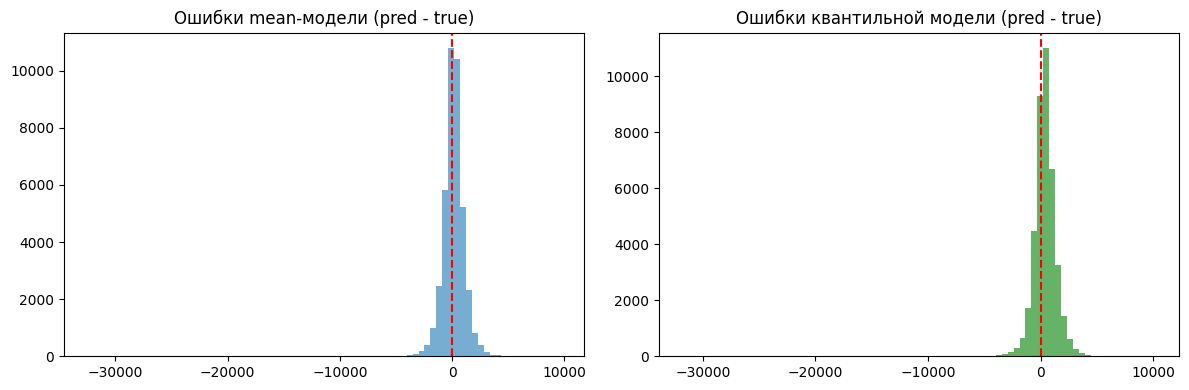

In [21]:
alpha_star = 2.0 / (2.0 + 1.0) # = 0.666...
print(f'Теоретический квантиль: {alpha_star:.3f}')

# Обучаем LightGBM с objective='quantile'
lgb_quant = lgb.LGBMRegressor(
    objective='quantile', alpha=alpha_star,
    n_estimators=best_params.get('n_estimators', 200),
    learning_rate=best_params.get('learning_rate', 0.1),
    num_leaves=best_params.get('num_leaves', 31),
    random_state=RANDOM_STATE, verbose=-1
)
lgb_quant.fit(X_train_fe, y_train_fe, categorical_feature=cat_cols)
pred_quant = lgb_quant.predict(X_test_fe)

def asym_cost(y_true, y_pred, c_under=2.0, c_over=1.0):
    err = y_pred - y_true
    return np.sum(c_under * np.maximum(-err, 0) + c_over * np.maximum(err, 0))

cost_mean  = asym_cost(y_test, pred_lgb)
cost_quant = asym_cost(y_test, pred_quant)

print(f'Суммарные потери (mean-модель): {cost_mean:,.0f}')
print(f'Суммарные потери (quantile 2/3): {cost_quant:,.0f}')
print(f'Экономия: {cost_mean - cost_quant:,.0f} ({(cost_mean - cost_quant)/cost_mean*100:.1f}%)')

# График (для отчета)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pred_lgb - y_test, bins=80, alpha=0.6, label='mean')
axes[0].axvline(0, color='red', ls='--')
axes[0].set_title('Ошибки mean-модели (pred - true)')
axes[1].hist(pred_quant - y_test, bins=80, alpha=0.6, color='green', label='quantile 2/3')
axes[1].axvline(0, color='red', ls='--')
axes[1].set_title('Ошибки квантильной модели (pred - true)')
plt.tight_layout(); plt.show()

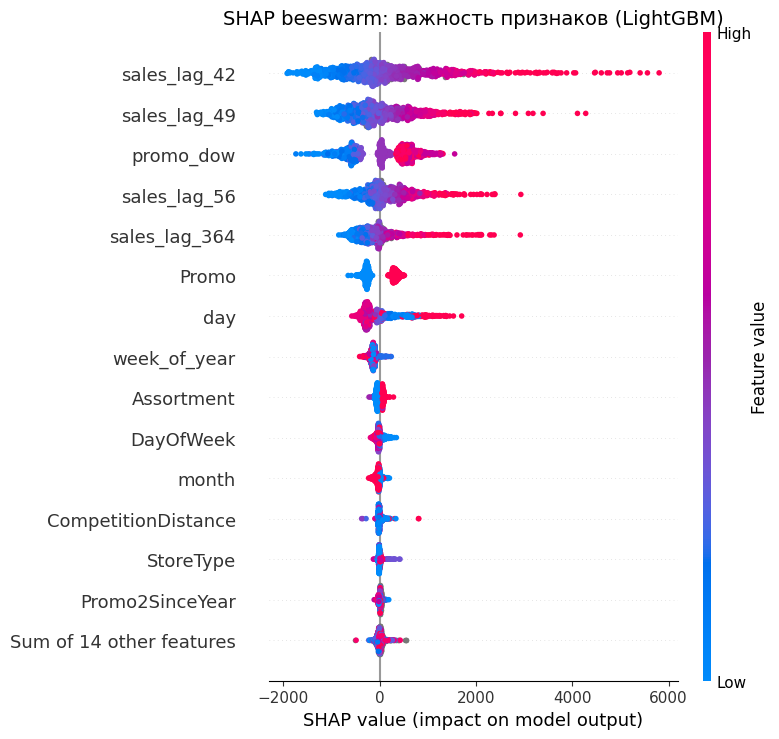

<Figure size 800x500 with 0 Axes>

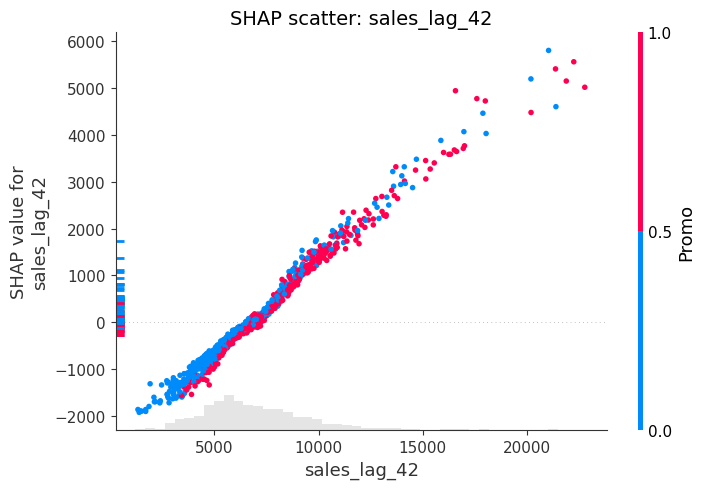

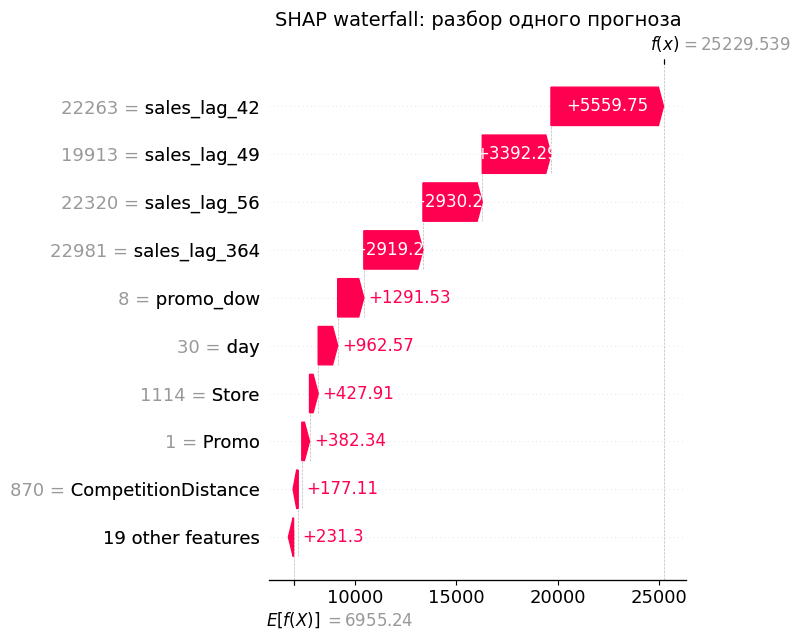

In [31]:
import shap

# 1. Берем подвыборку
X_expl = X_test_fe.sample(min(1000, len(X_test_fe)), random_state=RANDOM_STATE)

# 2. Переводим в числовой формат (категории в коды)
X_expl_codes = X_expl.copy()
for col in cat_cols:
    X_expl_codes[col] = X_expl[col].cat.codes

# 3. ГЛАВНОЕ ИСПРАВЛЕНИЕ: Переводим DataFrame в numpy array
# Это полностью отключает проверки LightGBM на совпадение категорий
X_expl_numpy = X_expl_codes.values
feature_names = list(X_expl.columns)

# 4. Создаем объяснитель от внутренней модели (booster)
explainer = shap.TreeExplainer(lgb_final.booster_)
# Передаем numpy array
sv_raw = explainer(X_expl_numpy)

# 5. Пересоздаем объект Explanation, чтобы отвязать его от pandas
sv = shap.Explanation(
    values=sv_raw.values,
    base_values=sv_raw.base_values,
    data=X_expl_numpy,
    feature_names=feature_names
)

# --- ГРАФИК 1: Beeswarm (Глобальная важность) ---
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP beeswarm: важность признаков (LightGBM)', fontsize=14)
plt.tight_layout()
plt.show()

# --- ГРАФИК 2: Scatter для ключевого признака ---
top_feat = 'sales_lag_42' if 'sales_lag_42' in X_expl.columns else X_expl.columns[0]
plt.figure(figsize=(8, 5))
shap.plots.scatter(sv[:, top_feat], color=sv, show=False)
plt.title(f'SHAP scatter: {top_feat}', fontsize=14)
plt.tight_layout()
plt.show()

# --- ГРАФИК 3: Waterfall (Разбор одного прогноза) ---
idx_high = np.argmax(lgb_final.predict(X_expl))
plt.figure(figsize=(10, 6))
shap.plots.waterfall(sv[idx_high], max_display=10, show=False)
plt.title('SHAP waterfall: разбор одного прогноза', fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
import joblib

# Сохраняем модель и параметры
bundle = {
    'model': lgb_final,
    'quantile_model': lgb_quant,
    'features': FEATURES,
    'cat_cols': cat_cols,
    'alpha': alpha_star,
    'best_params': best_params,
}
joblib.dump(bundle, 'model.joblib')

def column_schema(s):
    if pd.api.types.is_numeric_dtype(s):
        return {'type': 'number', 'min': float(s.min()), 'max': float(s.max())}
    return {'type': 'category', 'values': sorted(s.dropna().astype(str).unique().tolist())}

schema = {col: column_schema(train_fe[col]) for col in FEATURES}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print("Модель и схема сохранены!")

# Проверка
bundle_loaded = joblib.load('model.joblib')
assert np.allclose(bundle_loaded['model'].predict(X_test_fe[:5]), lgb_final.predict(X_test_fe[:5]))
print("Проверка загрузки: OK")

Модель и схема сохранены!
Проверка загрузки: OK


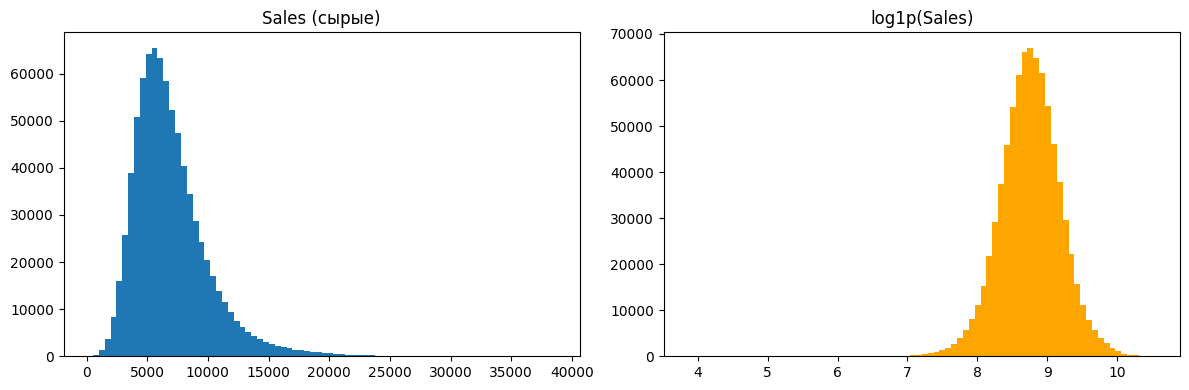

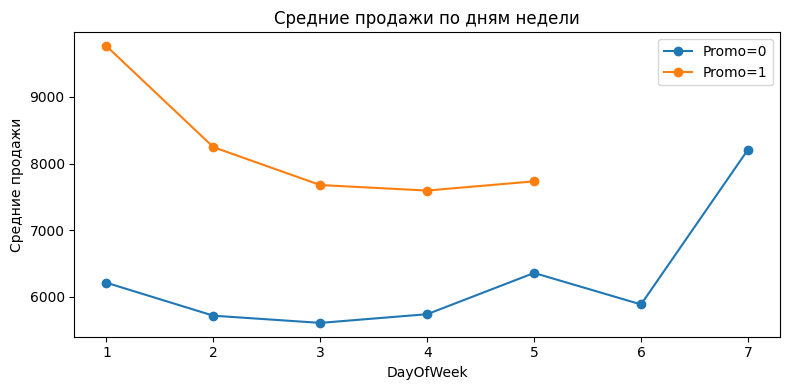

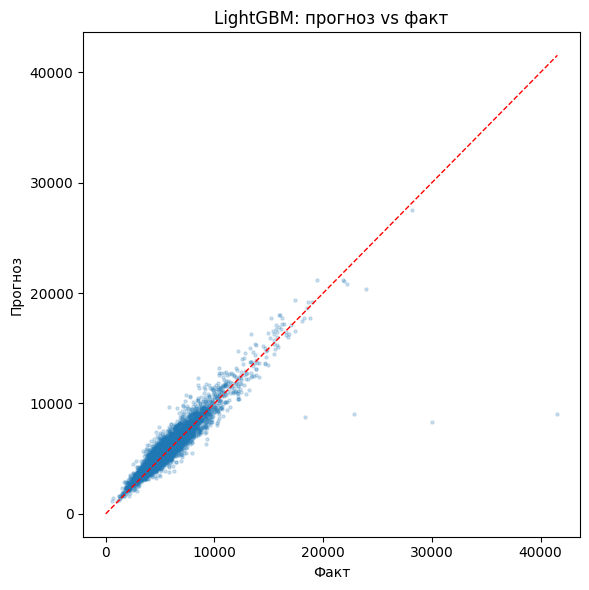

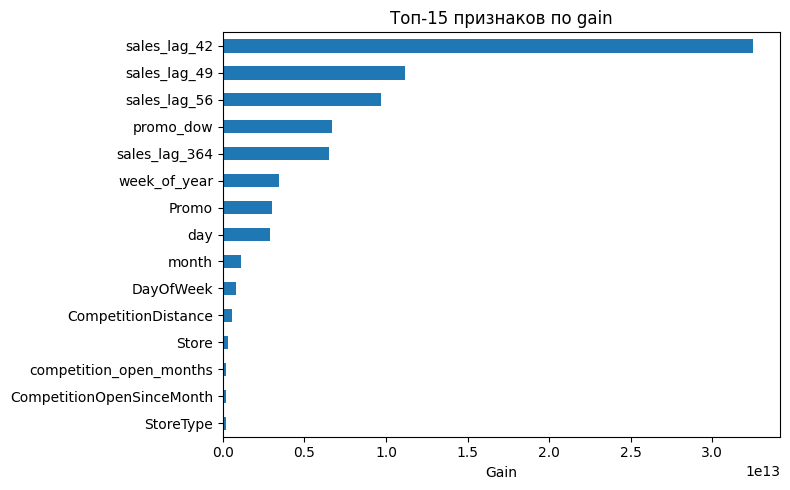

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df['Sales'], bins=80)
axes[0].set_title('Sales (сырые)')
axes[1].hist(np.log1p(train_df['Sales']), bins=80, color='orange')
axes[1].set_title('log1p(Sales)')
plt.tight_layout(); plt.show()

# B. Продажи по дням недели
fig, ax = plt.subplots(figsize=(8, 4))
for promo in [0, 1]:
    sub = train_df[train_df['Promo'] == promo].groupby('DayOfWeek')['Sales'].mean()
    ax.plot(sub.index, sub.values, marker='o', label=f'Promo={promo}')
ax.set_xlabel('DayOfWeek'); ax.set_ylabel('Средние продажи')
ax.set_title('Средние продажи по дням недели')
ax.legend(); plt.tight_layout(); plt.show()

# C. Прогноз vs Факт
plt.figure(figsize=(6, 6))
plt.scatter(y_test[:5000], pred_lgb[:5000], alpha=0.2, s=5)
mx = max(y_test[:5000].max(), pred_lgb[:5000].max())
plt.plot([0, mx], [0, mx], 'r--', lw=1)
plt.xlabel('Факт'); plt.ylabel('Прогноз')
plt.title('LightGBM: прогноз vs факт')
plt.tight_layout(); plt.show()

# D. Важность признаков (gain)
imp = pd.Series(lgb_final.booster_.feature_importance(importance_type='gain'),
                index=FEATURES).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
imp.plot(kind='barh')
plt.xlabel('Gain'); plt.title('Топ-15 признаков по gain')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()